In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
%matplotlib inline

In [2]:
batch_size = 2048
test_loss_list = []
acc_list = []
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train_loader = torch.utils.data.DataLoader(
        datasets.MNIST('data', train=True, download=True,
                       transform=transforms.Compose([
                           transforms.ToTensor(),
                       ])),
        batch_size=batch_size, shuffle=True)

test_loader = torch.utils.data.DataLoader(
        datasets.MNIST('data', train=False, transform=transforms.Compose([
                           transforms.ToTensor(),
                       ])),
        batch_size=batch_size, shuffle=True)

train_loader.dataset.data.shape,

(torch.Size([60000, 28, 28]),)

In [3]:
class mlp(nn.Module):
  def __init__(self):
    super(mlp,self).__init__()
    self.l1 = nn.Linear(784,128)
    self.l2 = nn.Linear(128,10)

  def forward(self,x):
    a1 = self.l1(x)
    x1 = F.relu(a1)
    a2 = self.l2(x1)
    return a2

In [4]:
model = mlp().to(device)
optimizer = optim.SGD(model.parameters(),lr=0.01)
model

mlp(
  (l1): Linear(in_features=784, out_features=128, bias=True)
  (l2): Linear(in_features=128, out_features=10, bias=True)
)

In [5]:
epochs = 10
for epoch in range(epochs):
  model.train()
  for batch_idx,(x,y) in enumerate(train_loader):
    x,y = x.view(x.shape[0],-1).to(device),y.to(device)
    optimizer.zero_grad()
    output = model(x)
    loss = F.cross_entropy(output,y)
    loss.backward()
    optimizer.step()

  model.eval()
  correct = 0
  test_loss = 0
  with torch.no_grad():
    for batch_idx,(x,y) in enumerate(test_loader):
      x,y = x.view(x.shape[0],-1).to(device),y.to(device)
      output = model(x)
      test_loss += F.cross_entropy(output,y)
      pred = output.max(1,keepdim=True)[1]
      correct += pred.eq(y.view_as(pred)).sum().item()

    test_loss = test_loss/(batch_idx+1)
    acc = correct/len(test_loader.dataset)
    
    print('epoch:{}, loss:{:.4f}, acc:{:.4f}'.format(epoch,test_loss,acc))
    
    test_loss_list.append(test_loss.cpu().item())
    acc_list.append(acc)

epoch:0, loss:2.2476, acc:0.2735
epoch:1, loss:2.1933, acc:0.4045
epoch:2, loss:2.1335, acc:0.4950
epoch:3, loss:2.0660, acc:0.5712
epoch:4, loss:1.9910, acc:0.6226
epoch:5, loss:1.9092, acc:0.6636
epoch:6, loss:1.8213, acc:0.6929
epoch:7, loss:1.7285, acc:0.7153
epoch:8, loss:1.6324, acc:0.7323
epoch:9, loss:1.5363, acc:0.7465


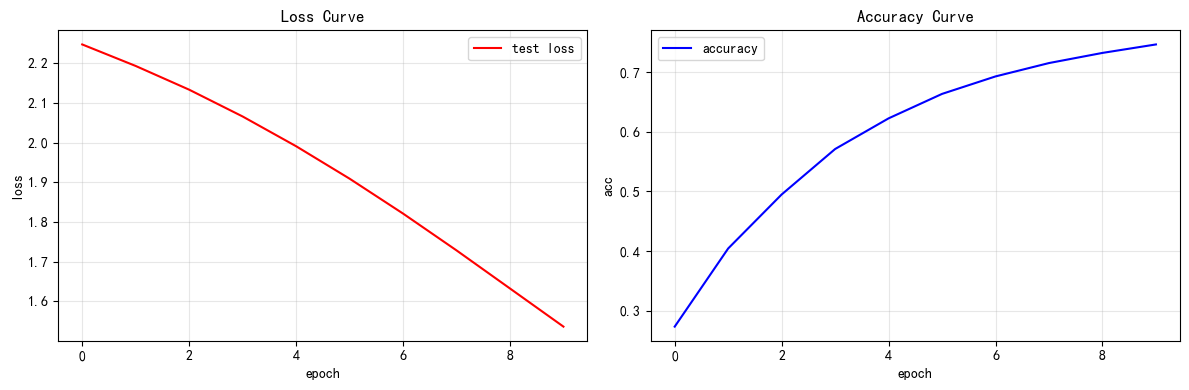

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))

ax1.plot(test_loss_list, c='r', label='test loss')
ax1.set_xlabel('epoch')
ax1.set_ylabel('loss')
ax1.set_title('Loss Curve')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(acc_list, c='b', label='accuracy')
ax2.set_xlabel('epoch')
ax2.set_ylabel('acc')
ax2.set_title('Accuracy Curve')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()



epoch  1: loss=0.4057, acc=0.8942
epoch  2: loss=0.2828, acc=0.9242
epoch  3: loss=0.2541, acc=0.9381
epoch  4: loss=0.2139, acc=0.9471
epoch  5: loss=0.1449, acc=0.9544
epoch  6: loss=0.1091, acc=0.9621
epoch  7: loss=0.0948, acc=0.9641
epoch  8: loss=0.0846, acc=0.9680
epoch  9: loss=0.0744, acc=0.9696
epoch 10: loss=0.0717, acc=0.9706


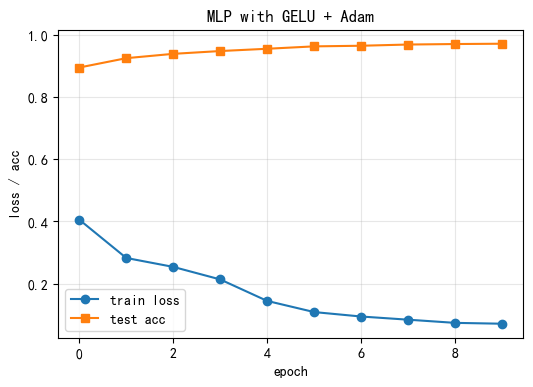

In [ ]:
class MLP2(nn.Module):

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512)   
        self.fc2 = nn.Linear(512, 256)   
        self.fc3 = nn.Linear(256, 10)    

    def forward(self, x):
        x = x.view(-1, 784)              
        x = F.gelu(self.fc1(x))          
        x = F.gelu(self.fc2(x))          
        return self.fc3(x)               


model2 = MLP2().to(device)                        
opt2 = optim.Adam(model2.parameters(), lr=1e-3)   

loss_list, acc_list2 = [], []                     

for epoch in range(10):                           
    model2.train()                                
    for x, y in train_loader:
        x = x.view(x.size(0), -1).to(device)      
        y = y.to(device)

        opt2.zero_grad()                          
        loss = F.cross_entropy(model2(x), y)      
        loss.backward()                           
        opt2.step()                               


    model2.eval()                                 
    correct = 0
    with torch.no_grad():                         
        for x, y in test_loader:
            x = x.view(x.size(0), -1).to(device)
            y = y.to(device)
            pred = model2(x).argmax(1)            
            correct += (pred == y).sum().item()   

    acc = correct / len(test_loader.dataset)      
    loss_list.append(loss.item())                 
    acc_list2.append(acc)
    print('epoch {:2d}: loss={:.4f}, acc={:.4f}'.format(epoch + 1, loss.item(), acc))

plt.figure(figsize=(6, 4))
plt.plot(loss_list, 'o-', label='train loss')
plt.plot(acc_list2, 's-', label='test acc')
plt.xlabel('epoch')
plt.ylabel('loss / acc')
plt.title('MLP with GELU + Adam')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

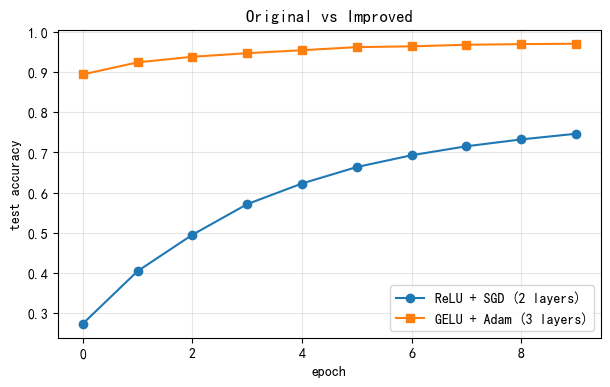

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(acc_list,  'o-', label='ReLU + SGD (2 layers)')
plt.plot(acc_list2, 's-', label='GELU + Adam (3 layers)')
plt.xlabel('epoch'); plt.ylabel('test accuracy')
plt.title('Original vs Improved')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

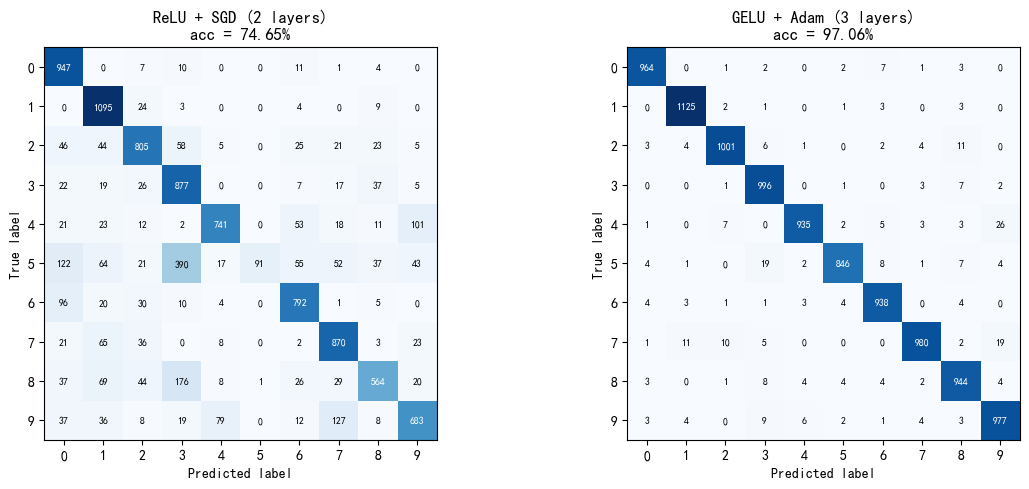

class   original   improved
  0       96.6%      98.4%
  1       96.5%      99.1%
  2       78.0%      97.0%
  3       86.8%      98.6%
  4       75.5%      95.2%
  5       10.2%      94.8%
  6       82.7%      97.9%
  7       84.6%      95.3%
  8       57.9%      96.9%
  9       67.7%      96.8%


In [ ]:
def get_preds(net, loader):
    net.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.view(x.size(0), -1).to(device)
            ps.append(net(x).argmax(1).cpu())   
            ys.append(y)                        #
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()


def conf_matrix(y_true, y_pred, n=10):
    cm = np.zeros((n, n), dtype=int)            
    np.add.at(cm, (y_true, y_pred), 1)
    return cm


y0, p0 = get_preds(model,  test_loader)
y1, p1 = get_preds(model2, test_loader)
cm0 = conf_matrix(y0, p0)
cm1 = conf_matrix(y1, p1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, cm, name in zip(axes, [cm0, cm1], ['ReLU + SGD (2 layers)', 'GELU + Adam (3 layers)']):
    ax.imshow(cm, cmap='Blues')
    ax.set_title('{}\nacc = {:.2f}%'.format(name, 100 * np.trace(cm) / cm.sum()))
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')

plt.tight_layout()
plt.show()

print('class   original   improved')
for i in range(10):
    a0 = 100 * cm0[i, i] / cm0[i].sum()
    a1 = 100 * cm1[i, i] / cm1[i].sum()
    print('  {}      {:5.1f}%     {:5.1f}%'.format(i, a0, a1))